# Phân tích kết quả

Tổng hợp từ các file trong `results/<CATEGORY>/` và đo xem sentiment của bình luận có thêm thông tin ngoài số sao hay không.

In [1]:
import sys; sys.path.append("..")
import json
import numpy as np, pandas as pd
from src.config import CATEGORY, CORE_FILE, DATA, RESULTS, SENT_FILE
from scipy.stats import spearmanr
print(CATEGORY)
print((DATA / "dataset_meta.json").read_text(encoding="utf-8") if (DATA / "dataset_meta.json").exists() else "")

Video_Games
{
  "category": "Video_Games",
  "source_url": "https://mcauleylab.ucsd.edu/public_datasets/data/amazon_2023/raw/review_categories/Video_Games.jsonl.gz",
  "raw_file": "Video_Games.jsonl.gz",
  "timestamp_field": "timestamp",
  "timestamp_unit": "ms",
  "core_start": 5,
  "core_chosen": 9,
  "max_reviews": 300000,
  "split": "leave-one-out theo timestamp, phá hòa theo parent_asin",
  "auto_title_cleaned": true,
  "n_user": 16886,
  "n_item": 7064,
  "n_review": 257475,
  "n_train": 223703,
  "n_valid": 16886,
  "n_test": 16886,
  "tie_rate_last2": 0.00011844131232974062,
  "generated_at": "2026-10-18T23:22:04"
}


## 1. Baseline

In [2]:
display(pd.read_csv(RESULTS / "baselines_test.csv").round(4))

,model,HR@10,HR@10 lo,HR@10 hi,NDCG@10,NDCG@10 lo,NDCG@10 hi,n_eval
0,Popularity,0.0293,0.0268,0.0320,0.0137,0.0124,0.0151,16886
1,ItemKNN,0.0737,0.0699,0.0775,0.0386,0.0363,0.0407,16886
2,ItemKNN+pop,0.0737,0.0699,0.0775,0.0386,0.0363,0.0407,16886
3,EASE,0.0807,0.0767,0.0847,0.0432,0.0407,0.0456,16886
4,EASE+pop,0.0806,0.0766,0.0847,0.0432,0.0407,0.0456,16886


## 2. Tác động của sentiment lên NDCG@10

Hình dưới vẽ chênh lệch NDCG@10 so với baseline cùng thuật toán nền, kèm khoảng tin cậy 95% (đường đậm) và khoảng đã hiệu chỉnh Bonferroni (đường nhạt). Biến thể chỉ đáng kể khi khoảng tin cậy không chứa 0.

,algo,family,params,HR@10,NDCG@10,dNDCG@10,lo,hi,lo_bonf,hi_bonf,khác baseline (95%),khác baseline (Bonferroni)
1,knn,B stars,"{""alpha"": 1.0, ""gamma"": 0.5}",0.0717,0.0377,-0.0009,-0.0017,-0.0001,-0.0019,0.0001,True,False
2,knn,C sentiment,"{""alpha"": 0.0, ""mode"": ""raw"", ""gamma"": 1}",0.0717,0.0376,-0.0010,-0.0020,0.0001,-0.0023,0.0004,False,False
3,knn,D stars+sentiment,"{""alpha"": 0.75, ""mode"": ""rank"", ""gamma"": 1.0}",0.0728,0.0378,-0.0008,-0.0018,0.0002,-0.0021,0.0006,False,False
4,knn,E prior sentiment,"{""lam"": 0.1}",0.0715,0.0374,-0.0011,-0.0021,-0.0002,-0.0025,0.0002,True,False
5,knn,E prior stars,"{""lam"": 0.1}",0.0713,0.0373,-0.0013,-0.0022,-0.0004,-0.0026,-0.0000,True,True
6,knn,F drop low sentiment,"{""drop"": ""sent"", ""q"": 0.05}",0.0718,0.0375,-0.0011,-0.0019,-0.0003,-0.0021,-0.0000,True,True
7,knn,F drop low stars,"{""drop"": ""stars"", ""thr"": 2}",0.0709,0.0370,-0.0015,-0.0025,-0.0006,-0.0028,-0.0003,True,True
9,ease,B stars,"{""alpha"": 1.0, ""gamma"": 0.5}",0.0794,0.0429,-0.0002,-0.0012,0.0006,-0.0014,0.0009,False,False
10,ease,C sentiment,"{""alpha"": 0.0, ""mode"": ""raw"", ""gamma"": 1}",0.0789,0.0425,-0.0007,-0.0018,0.0004,-0.0023,0.0009,False,False
11,ease,D stars+sentiment,"{""alpha"": 0.75, ""mode"": ""rank"", ""gamma"": 1.0}",0.0796,0.0431,-0.0001,-0.0012,0.0010,-0.0016,0.0014,False,False


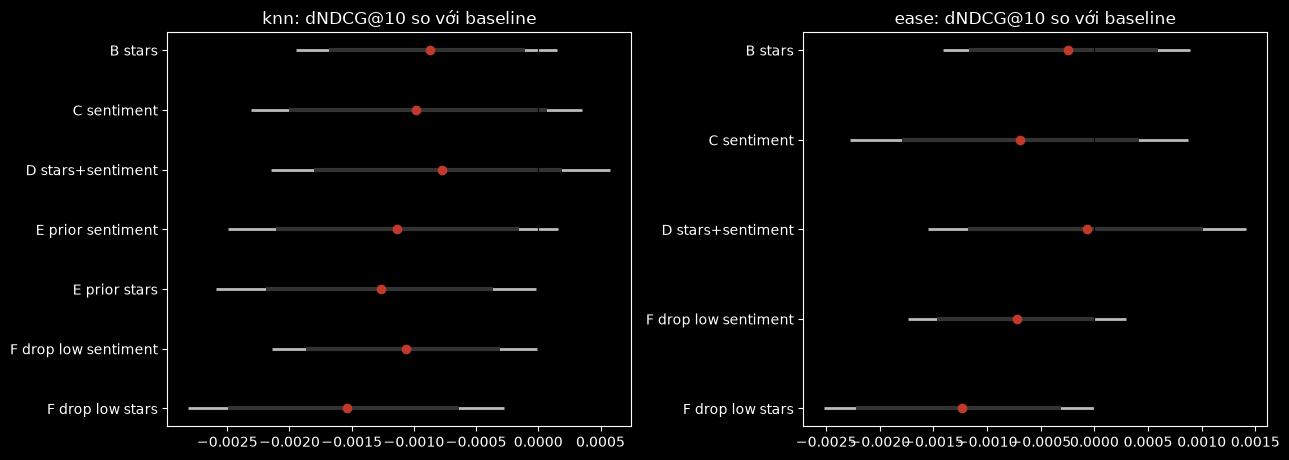

In [3]:
res = pd.read_csv(RESULTS / "hybrid_test.csv")
res = res[res.family != "A baseline"].copy()
display(res.round(4))
try:
    import matplotlib.pyplot as plt
    algos = list(res.algo.unique())
    fig, axes = plt.subplots(1, len(algos), figsize=(6.5 * len(algos), 0.45 * len(res) / len(algos) + 2), squeeze=False)
    for ax, algo in zip(axes[0], algos):
        r = res[res.algo == algo].reset_index(drop=True)
        y = np.arange(len(r))
        ax.hlines(y, r.lo_bonf, r.hi_bonf, color="#bbbbbb", lw=2)
        ax.hlines(y, r.lo, r.hi, color="#333333", lw=3)
        ax.plot(r["dNDCG@10"], y, "o", color="#c0392b")
        ax.axvline(0, color="k", lw=0.8)
        ax.set_yticks(y); ax.set_yticklabels(r.family); ax.invert_yaxis()
        ax.set_title(f"{algo}: dNDCG@10 so với baseline")
    plt.tight_layout(); plt.show()
except ImportError:
    print("Chưa cài matplotlib.")

### Sentiment so với số sao

C (chỉ sentiment) và D (sao + sentiment) so với B (chỉ số sao), bootstrap ghép cặp, khoảng tin cậy 95% đã hiệu chỉnh Bonferroni cho 2 phép so sánh. Đây là phép so sánh trả lời câu hỏi chính: sentiment có thêm thông tin ngoài số sao hay không.

In [4]:
display(pd.read_csv(RESULTS / "hybrid_vs_stars_test.csv").round(4))

,algo,family,so với,dNDCG@10,lo,hi,khác 0
0,knn,C sentiment,B stars,-0.0001,-0.0010,0.0008,False
1,knn,D stars+sentiment,B stars,0.0001,-0.0006,0.0008,False
2,ease,C sentiment,B stars,-0.0004,-0.0014,0.0005,False
3,ease,D stars+sentiment,B stars,0.0002,-0.0005,0.0009,False


## 3. Phân tầng

In [5]:
display(pd.read_csv(RESULTS / "hybrid_strata_test.csv").round(4))

,algo,family,tầng,n,NDCG@10 baseline,NDCG@10 biến thể,d,lo,hi,khác 0
0,knn,B stars,tất cả,16886,0.0386,0.0377,-0.0009,-0.0017,-0.0001,True
1,knn,B stars,đích <= 3 sao,3582,0.0208,0.0179,-0.0028,-0.0052,-0.0007,True
2,knn,B stars,đích >= 4 sao,13304,0.0433,0.0430,-0.0003,-0.0012,0.0005,False
3,knn,B stars,đích được khen hơn thường lệ,9513,0.0405,0.0401,-0.0004,-0.0014,0.0007,False
4,knn,B stars,đích được khen ít hơn thường lệ,7136,0.0339,0.0324,-0.0016,-0.0030,-0.0003,True
5,knn,C sentiment,tất cả,16886,0.0386,0.0376,-0.0010,-0.0020,0.0001,False
6,knn,C sentiment,đích <= 3 sao,3582,0.0208,0.0171,-0.0037,-0.0061,-0.0014,True
7,knn,C sentiment,đích >= 4 sao,13304,0.0433,0.0431,-0.0003,-0.0014,0.0010,False
8,knn,C sentiment,đích được khen hơn thường lệ,9513,0.0405,0.0403,-0.0002,-0.0016,0.0012,False
9,knn,C sentiment,đích được khen ít hơn thường lệ,7136,0.0339,0.0318,-0.0022,-0.0039,-0.0005,True


## 4. Sentiment có thêm thông tin ngoài số sao không?

Nếu điểm sentiment gần như chỉ lặp lại số sao thì không có gì để cải thiện, bất kể thuật toán. Bảng dưới đo mức tương quan với số sao, độ phân tán trong từng mức sao, và tỉ lệ review mà bình luận "bất đồng" với số sao.

In [6]:
core = pd.read_csv(CORE_FILE, usecols=["user_id", "parent_asin", "rating", "text"])
core["n_words"] = core.text.fillna("").str.split().str.len().fillna(0).astype(int)
sa = pd.read_csv(SENT_FILE)
d = core.merge(sa, on=["user_id", "parent_asin"], validate="1:1")
for col in [c for c in ("vader01", "tf01") if c in d.columns]:
    x = d.dropna(subset=[col])
    print(f"\n== {col}: {len(x):,} review có điểm")
    print("Spearman với sao:", round(spearmanr(x[col], x.rating).statistic, 3))
    print(x.groupby("rating")[col].agg(["mean", "std", "size"]).round(3).to_string())
    long = x[x.n_words >= 15]
    print(f"Review >= 15 từ: {len(long):,}; Spearman với sao: {spearmanr(long[col], long.rating).statistic:.3f}")
    # bất đồng: quy sentiment về thang sao 1-5 rồi so với số sao
    s5 = 1 + 4 * x[col]
    print("lệch >= 2 sao giữa sentiment và số sao:", round(((s5 - x.rating).abs() >= 2).mean(), 3))


== vader01: 257,447 review có điểm
Spearman với sao: 0.204
         mean    std    size
rating                      
1.0     0.425  0.338   14005
2.0     0.544  0.369   11080
3.0     0.700  0.327   23652
4.0     0.835  0.242   45346
5.0     0.854  0.181  163364
Review >= 15 từ: 176,534; Spearman với sao: 0.314
lệch >= 2 sao giữa sentiment và số sao: 0.107

== tf01: 257,447 review có điểm
Spearman với sao: 0.693
         mean    std    size
rating                      
1.0     0.150  0.140   14005
2.0     0.278  0.149   11080
3.0     0.467  0.170   23652
4.0     0.686  0.162   45346
5.0     0.846  0.147  163364
Review >= 15 từ: 176,534; Spearman với sao: 0.737
lệch >= 2 sao giữa sentiment và số sao: 0.029


## 5. Lượt trúng là item user thích hay không thích?

NDCG@10 coi item đích là trúng dù user sau đó chấm 1 đến 3 sao, nên một hệ thống tránh được item bị chê vẫn bị phạt. Bảng dưới tách lượt trúng top 10 thành hai loại: đích được chấm ≥4 sao và đích được chấm ≤3 sao (đơn vị: % số user test). Δ là chênh lệch so với baseline, kèm khoảng tin cậy 95% bootstrap ghép cặp. Nếu sentiment giúp tránh item bị chê, Δ của nhóm ≤3 sao phải âm rõ hơn Δ của nhóm ≥4 sao.

In [7]:
from src.config import SPLITS
from src.metrics import sort_targets
from src.stats import mean_ci

def slug(s):
    return "".join(ch if ch.isalnum() else "_" for ch in s).strip("_")

low = (sort_targets(pd.read_csv(SPLITS / "test.csv.gz")).rating <= 3).to_numpy()

def hits(algo, fam):
    rk = np.load(RESULTS / f"ranks_hybrid_{algo}_{slug(fam)}.npy")
    return ((rk < 10) & ~low).astype(float), ((rk < 10) & low).astype(float)

rows = []
for algo in res.algo.unique():
    good_a, bad_a = hits(algo, "A baseline")
    rows.append({"algo": algo, "family": "A baseline",
                 "trúng đích >=4 sao (%)": 100 * good_a.mean(), "trúng đích <=3 sao (%)": 100 * bad_a.mean()})
    for fam in res[res.algo == algo].family:
        good, bad = hits(algo, fam)
        dg, glo, ghi = (100 * v for v in mean_ci(good - good_a))
        db, blo, bhi = (100 * v for v in mean_ci(bad - bad_a))
        rows.append({"algo": algo, "family": fam,
                     "trúng đích >=4 sao (%)": 100 * good.mean(), "trúng đích <=3 sao (%)": 100 * bad.mean(),
                     "d >=4 sao": dg, "lo >=4": glo, "hi >=4": ghi,
                     "d <=3 sao": db, "lo <=3": blo, "hi <=3": bhi})
display(pd.DataFrame(rows).round(3))

,algo,family,trúng đích >=4 sao (%),trúng đích <=3 sao (%),d >=4 sao,lo >=4,hi >=4,d <=3 sao,lo <=3,hi <=3
0,knn,A baseline,6.443,0.924,NaN,NaN,NaN,NaN,NaN,NaN
1,knn,B stars,6.325,0.841,-0.118,-0.290,0.030,-0.083,-0.178,0.012
2,knn,C sentiment,6.396,0.770,-0.047,-0.237,0.148,-0.154,-0.255,-0.059
3,knn,D stars+sentiment,6.497,0.788,0.053,-0.148,0.243,-0.136,-0.237,-0.030
4,knn,E prior sentiment,6.420,0.728,-0.024,-0.225,0.172,-0.195,-0.284,-0.107
5,knn,E prior stars,6.408,0.722,-0.036,-0.237,0.154,-0.201,-0.296,-0.113
6,knn,F drop low sentiment,6.354,0.823,-0.089,-0.231,0.053,-0.101,-0.195,-0.006
7,knn,F drop low stars,6.343,0.746,-0.101,-0.278,0.065,-0.178,-0.296,-0.065
8,ease,A baseline,7.106,0.953,NaN,NaN,NaN,NaN,NaN,NaN
9,ease,B stars,7.148,0.794,0.041,-0.136,0.207,-0.160,-0.255,-0.077
